# Stock Prediction: Naive vs Random Forest (AAPL vs SPY)


I made the following steps for this stock prediction analysis:


- **Start with data** (download + basic checks)


- **Explore** (prices, returns, volatility)


- **Model** (a simple naive baseline, then a stronger Random Forest)


- **Visualize + $10,000 test** (if I invest with each approach, which ends higher?)

## 1) Data


We’ll pull daily prices from Yahoo Finance, then focus on the **last 10 years** as our out-of-sample-style demo window.

In [24]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-darkgrid")

try:
    import yfinance as yf
except ImportError as e:
    raise ImportError("Missing dependency") from e

# --- You can change these ---
TICKERS = ["AAPL", "SPY"]
START = "2008-01-01"
END = None  # up to today
BACKTEST_YEARS = 10
TEST_FRACTION = 0.30  # last 30% of the backtest window is our test set
INITIAL_CAPITAL = 10_000
RANDOM_STATE = 42


def download_close_prices(tickers, start, end=None):
    """Download daily close prices robustly across yfinance versions."""
    raw = yf.download(
        tickers=tickers,
        start=start,
        end=end,
        auto_adjust=False,
        progress=False,
        group_by="column",
        threads=True,
    )

    if raw.empty:
        raise ValueError("No data downloaded")

    # Prefer Adjusted Close when available; otherwise use Close.
    if isinstance(raw.columns, pd.MultiIndex):
        if "Adj Close" in raw.columns.get_level_values(0):
            close = raw["Adj Close"].copy()
        elif "Close" in raw.columns.get_level_values(0):
            close = raw["Close"].copy()
        else:
            raise ValueError(f"Unexpected columns from yfinance: {raw.columns}")
    else:
        # Single ticker case
        if "Adj Close" in raw.columns:
            close = raw[["Adj Close"]].rename(columns={"Adj Close": tickers[0]})
        elif "Close" in raw.columns:
            close = raw[["Close"]].rename(columns={"Close": tickers[0]})
        else:
            raise ValueError(f"Unexpected columns from yfinance: {raw.columns}")

    close = close.dropna(how="all").sort_index()
    return close


def synthetic_prices(tickers, years, seed=42):
    """Fallback dataset: simple random-walk prices so the notebook runs offline."""
    rng = np.random.default_rng(seed)
    n = int(years * 252 + 60)  # a bit extra for rolling windows
    dates = pd.date_range(end=pd.Timestamp.today().normalize(), periods=n, freq="B")
    out = pd.DataFrame(index=dates)
    for t in tickers:
        # log-returns: small drift + noise
        r = rng.normal(loc=0.0002, scale=0.012, size=n)
        out[t] = 100 * np.exp(np.cumsum(r))
    return out


try:
    prices = download_close_prices(TICKERS, START, END).dropna(how="any")
except Exception as e:
    print("yfinance download failed; running with synthetic data instead.")
    print("Reason:", repr(e))
    prices = synthetic_prices(TICKERS, years=BACKTEST_YEARS + 5, seed=RANDOM_STATE)

# Focus on the most recent N years as the demo window
cutoff_date = prices.index.max() - pd.DateOffset(years=BACKTEST_YEARS)
prices_bt = prices.loc[prices.index >= cutoff_date].copy()
returns_bt = prices_bt.pct_change().dropna()

print(f"Backtest window ({BACKTEST_YEARS}y): {prices_bt.index.min().date()} → {prices_bt.index.max().date()}")
print("Rows in backtest:", len(prices_bt))

display(prices_bt.tail())


2 Failed downloads:
['AAPL', 'SPY']: YFRateLimitError('Too Many Requests. Rate limited. Try after a while.')


yfinance download failed; running with synthetic data instead.
Reason: ValueError('No data downloaded')
Backtest window (10y): 2016-04-11 → 2026-04-10
Rows in backtest: 2610


,AAPL,SPY
2026-04-06,118.306696,212.932741
2026-04-07,119.154174,212.452204
2026-04-08,118.980744,210.903937
2026-04-09,118.550329,209.928737
2026-04-10,118.332985,208.089730


In [25]:
prices_bt.head(10)

,AAPL,SPY
2016-04-11,84.872309,58.421762
2016-04-12,83.753223,58.399208
2016-04-13,82.588060,59.767843
2016-04-14,82.690372,59.581177
2016-04-15,83.032102,60.485636
2016-04-18,82.262634,60.526086
2016-04-19,82.305342,60.840731
2016-04-20,82.887350,60.904008
2016-04-21,83.521221,61.539128
2016-04-22,85.108193,61.047168


## 2) Quick exploration (EDA)


Before modeling, we’ll sanity-check the data and look at basic behavior: prices, returns, and volatility.

Backtest data shape (prices): (2610, 2)
Backtest data shape (returns): (2609, 2)


,min,max,mean,std
AAPL,37.224071,122.123639,71.383891,22.620448
SPY,58.399208,309.980353,173.169864,70.164003


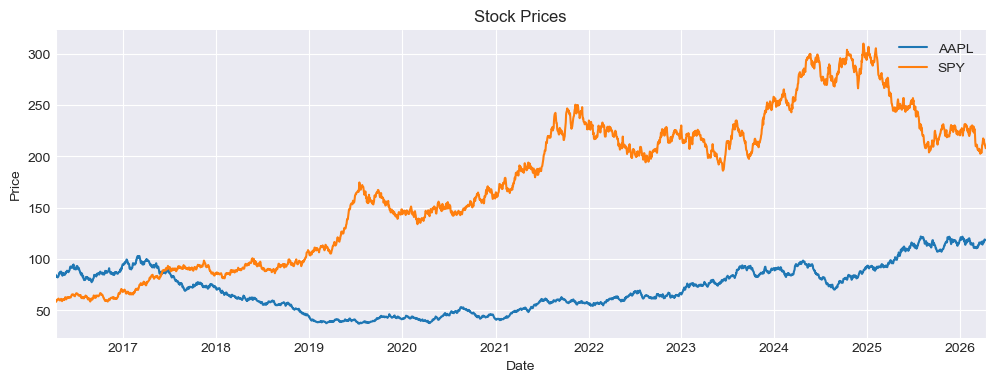

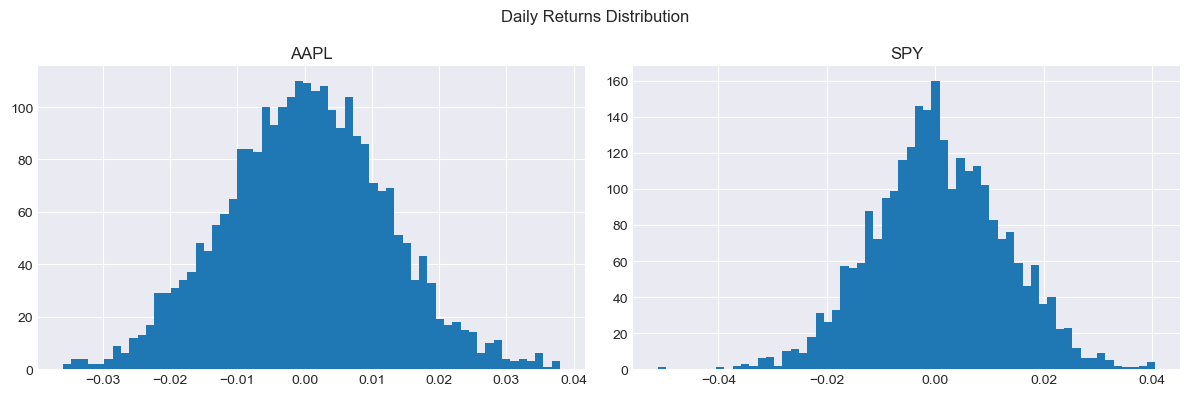

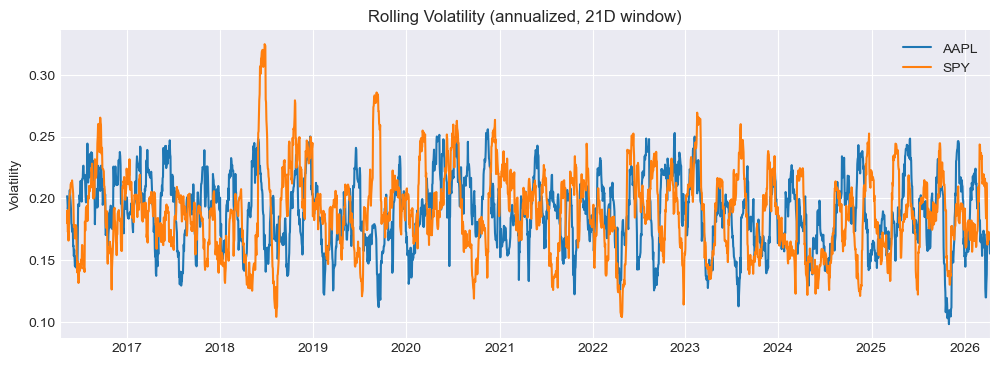

,AAPL,SPY
AAPL,1.000000,-0.023007
SPY,-0.023007,1.000000


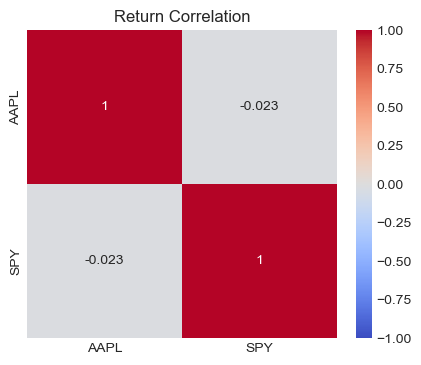

In [26]:
print("Backtest data shape (prices):", prices_bt.shape)
print("Backtest data shape (returns):", returns_bt.shape)

display(prices_bt.describe().T[["min", "max", "mean", "std"]])

# 1) Price chart
ax = prices_bt.plot(figsize=(12, 4), linewidth=1.5, title="Stock Prices")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
plt.show()

# 2) Daily return histograms (quick feel for distribution)
returns_bt.hist(bins=60, figsize=(12, 4), layout=(1, len(TICKERS)))
plt.suptitle("Daily Returns Distribution")
plt.tight_layout()
plt.show()

# 3) Rolling annualized volatility (21 trading days ≈ 1 month)
rolling_vol = returns_bt.rolling(21).std() * np.sqrt(252)
ax = rolling_vol.plot(figsize=(12, 4), title="Rolling Volatility (annualized, 21D window)")
ax.set_ylabel("Volatility")
plt.show()

# 4) Correlation between tickers (returns)
corr = returns_bt.corr()
display(corr)

try:
    import seaborn as sns
    plt.figure(figsize=(5, 4))
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Return Correlation")
    plt.show()
except ImportError:
    plt.figure(figsize=(4, 3))
    plt.imshow(corr.values, vmin=-1, vmax=1)
    plt.xticks(range(len(corr.columns)), corr.columns)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Return Correlation")
    plt.colorbar()
    plt.show()

## 3) Features + target


We’ll predict a very simple target: **will tomorrow’s return be positive?**




Then we’ll build lightweight features from past returns (lags + rolling averages/volatility).

In [27]:
def make_supervised_frame(price: pd.Series) -> pd.DataFrame:
    """Create a simple supervised dataset from a price series.

    Rows are 'today' (t).
    - Features use information available up to day t
    - Target/label is based on next-day return (t -> t+1)
    """
    df = pd.DataFrame(index=price.index)
    df["close"] = price
    df["ret1"] = price.pct_change()

    # Lagged returns (what we knew by end of day t)
    for lag in range(1, 6):
        df[f"lag_{lag}"] = df["ret1"].shift(lag)

    # Rolling features (still only using past data)
    df["roll_mean_5"] = df["ret1"].rolling(5).mean()
    df["roll_mean_10"] = df["ret1"].rolling(10).mean()
    df["roll_std_10"] = df["ret1"].rolling(10).std()
    df["ma_ratio_10_50"] = price.rolling(10).mean() / price.rolling(50).mean() - 1

    # What happens tomorrow?
    df["future_ret1"] = df["ret1"].shift(-1)
    df["target_up"] = (df["future_ret1"] > 0).astype(int)

    return df.dropna()


feature_cols = [
    "lag_1","lag_2","lag_3","lag_4","lag_5",
    "roll_mean_5","roll_mean_10","roll_std_10",
    "ma_ratio_10_50",
]

dataset = {}
for t in TICKERS:
    df = make_supervised_frame(prices_bt[t])
    split_idx = int(len(df) * (1 - TEST_FRACTION))
    train = df.iloc[:split_idx].copy()
    test = df.iloc[split_idx:].copy()

    dataset[t] = {
        "train": train,
        "test": test,
        "X_train": train[feature_cols],
        "y_train": train["target_up"],
        "X_test": test[feature_cols],
        "y_test": test["target_up"],
        "future_ret_test": test["future_ret1"],
    }

    print(f"{t}: total rows={len(df)}, train={len(train)} ({train.index.min().date()}→{train.index.max().date()}), test={len(test)} ({test.index.min().date()}→{test.index.max().date()})")

AAPL: total rows=2560, train=1792 (2016-06-17→2023-05-01), test=768 (2023-05-02→2026-04-09)
SPY: total rows=2560, train=1792 (2016-06-17→2023-05-01), test=768 (2023-05-02→2026-04-09)


In [ ]:
train

,close,ret1,lag_1,lag_2,lag_3,lag_4,lag_5,roll_mean_5,roll_mean_10,roll_std_10,ma_ratio_10_50,future_ret1,target_up
2016-06-17,65.462311,0.008080,-0.008259,-0.002196,0.009888,0.007252,0.020158,0.002953,0.004037,0.008427,0.042119,0.002257,1
2016-06-20,65.610088,0.002257,0.008080,-0.008259,-0.002196,0.009888,0.007252,0.001954,0.004468,0.008188,0.044294,-0.016730,0
2016-06-21,64.512430,-0.016730,0.002257,0.008080,-0.008259,-0.002196,0.009888,-0.003369,0.003057,0.010449,0.045315,-0.003730,0
2016-06-22,64.271808,-0.003730,-0.016730,0.002257,0.008080,-0.008259,-0.002196,-0.003676,0.002651,0.010643,0.046454,-0.000794,0
2016-06-23,64.220747,-0.000794,-0.003730,-0.016730,0.002257,0.008080,-0.008259,-0.002183,0.001593,0.010377,0.046474,-0.005908,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-04-25,198.738451,-0.012040,0.009358,-0.009787,0.005812,-0.008561,0.016625,-0.003044,-0.005456,0.011609,-0.066022,0.000671,1
2023-04-26,198.871797,0.000671,-0.012040,0.009358,-0.009787,0.005812,-0.008561,-0.001197,-0.003975,0.011319,-0.068332,0.000835,1
2023-04-27,199.037768,0.000835,0.000671,-0.012040,0.009358,-0.009787,0.005812,-0.002193,-0.002678,0.011020,-0.068904,0.028533,1
2023-04-28,204.716943,0.028533,0.000835,0.000671,-0.012040,0.009358,-0.009787,0.005471,0.001892,0.013532,-0.065569,0.007795,1


## 4) Models


### 4a) Naive baseline


A very simple baseline is: **tomorrow’s direction = yesterday’s direction**.


This is not meant to be “good” — it’s meant to be easy to understand and to beat.

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Naive baseline: predict "up" tomorrow if yesterday's return was positive
strategy_returns = {}
naive_metrics = []

for t in TICKERS:
    X_test = dataset[t]["X_test"]
    y_test = dataset[t]["y_test"]
    future_ret_test = dataset[t]["future_ret_test"]

    pred_up = (X_test["lag_1"] > 0).astype(int)
    accuracy = accuracy_score(y_test, pred_up)

    # Long/cash rule: if we predict up, we hold for the next day; otherwise we sit in cash
    ret = pd.DataFrame(index=X_test.index)
    ret["BuyHold"] = future_ret_test
    ret["Naive"] = pred_up * future_ret_test
    strategy_returns[t] = ret

    naive_metrics.append({
        "Ticker": t,
        "Naive accuracy": accuracy,
        "Naive market exposure": pred_up.mean(),
    })

naive_metrics_df = pd.DataFrame(naive_metrics).set_index("Ticker")
display(naive_metrics_df.style.format({"Naive accuracy": "{:.2%}", "Naive market exposure": "{:.2%}"}))

,Naive accuracy,Naive market exposure
Ticker,,
AAPL,50.26%,51.56%
SPY,54.56%,48.83%


### 4b) Random Forest (advanced)


Random Forest can learn **non-linear combinations** of the same simple features. We’ll train it on the training period, then evaluate on the held-out test period.

,RF accuracy,RF market exposure
Ticker,,
AAPL,52.73%,53.52%
SPY,49.61%,57.42%


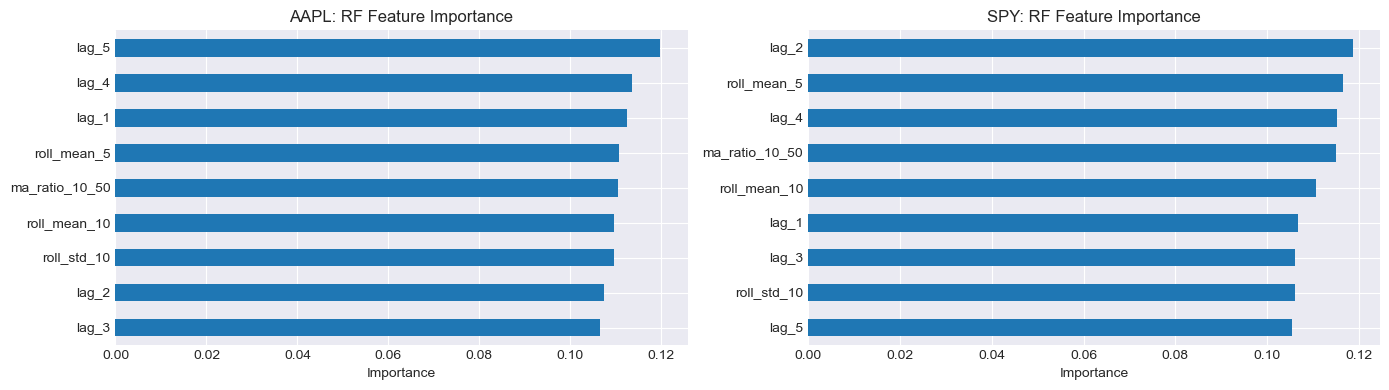

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_models = {}
rf_metrics = []

for t in TICKERS:
    X_train = dataset[t]["X_train"]
    y_train = dataset[t]["y_train"]
    X_test = dataset[t]["X_test"]
    y_test = dataset[t]["y_test"]
    future_ret_test = dataset[t]["future_ret_test"]

    model = RandomForestClassifier(
        n_estimators=400,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=5,
    )
    model.fit(X_train, y_train)

    proba_up = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index, name="p_up")
    pred_up = (proba_up >= 0.5).astype(int)

    # Store model and add RF strategy returns alongside BuyHold/Naive
    rf_models[t] = model
    strategy_returns[t]["RF"] = pred_up * future_ret_test

    rf_metrics.append({
        "Ticker": t,
        "RF accuracy": accuracy_score(y_test, pred_up),
       #  "RF precision": precision_score(y_test, pred_up, zero_division=0),
       #  "RF recall": recall_score(y_test, pred_up, zero_division=0),
        "RF market exposure": pred_up.mean(),
    })

rf_metrics_df = pd.DataFrame(rf_metrics).set_index("Ticker")
display(rf_metrics_df.style.format({
    "RF accuracy": "{:.2%}",
#     "RF precision": "{:.2%}",
#     "RF recall": "{:.2%}",
    "RF market exposure": "{:.2%}",
}))

# Feature importance (quick interpretability)
fig, axes = plt.subplots(1, len(TICKERS), figsize=(14, 4), sharex=False)
if len(TICKERS) == 1:
    axes = [axes]

for ax, t in zip(axes, TICKERS):
    imp = pd.Series(rf_models[t].feature_importances_, index=feature_cols).sort_values()
    imp.plot(kind="barh", ax=ax, title=f"{t}: RF Feature Importance")
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()

## 5) The $10,000 test (simple backtest)


Rule for both models: **if the model predicts “up”, we invest for the next day; otherwise we stay in cash.**




We’ll compare three curves on the same test period: **Buy & Hold**, **Naive**, and **Random Forest**.

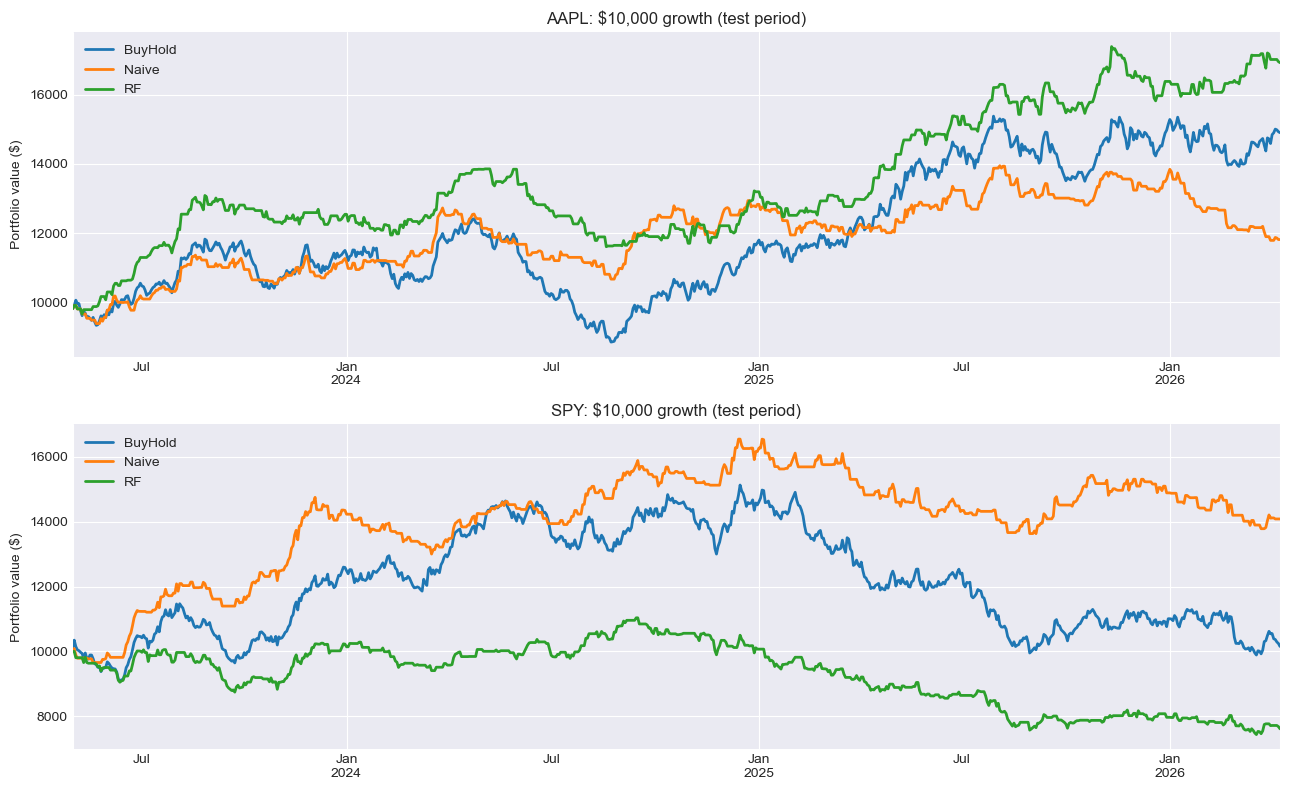

,BuyHold,Naive,RF
2026-04-03 00:00:00,"$25,288","$25,905","$24,732"
2026-04-06 00:00:00,"$25,372","$25,958","$24,732"
2026-04-07 00:00:00,"$25,274","$25,940","$24,732"
2026-04-08 00:00:00,"$25,172","$25,897","$24,635"
2026-04-09 00:00:00,"$25,055","$25,897","$24,537"


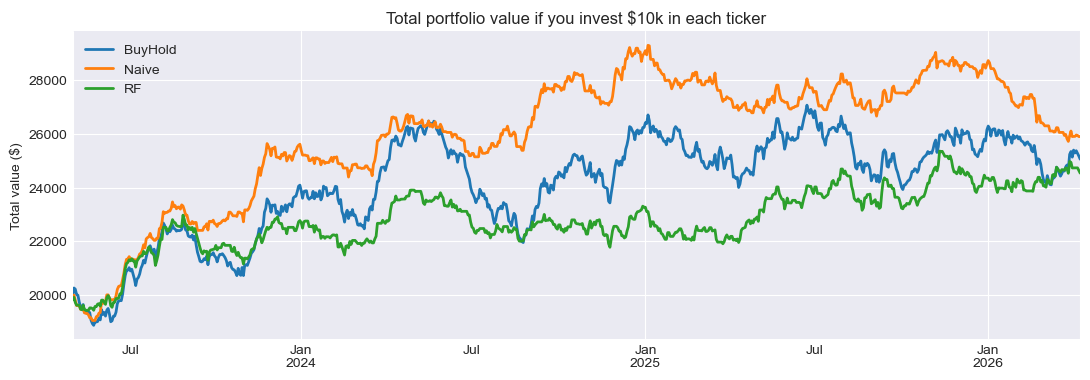

Final total values (higher is better):


,Final Total ($)
Naive,"$25,897"
BuyHold,"$25,055"
RF,"$24,537"


In [31]:
def cumulative_curve(ret_series: pd.Series, initial_capital: float) -> pd.Series:
    return initial_capital * (1 + ret_series).cumprod()


def max_drawdown(curve: pd.Series) -> float:
    peak = curve.cummax()
    dd = curve / peak - 1
    return float(dd.min())


def annualized_sharpe(ret_series: pd.Series, periods_per_year: int = 252) -> float:
    mu = ret_series.mean()
    sigma = ret_series.std()
    if sigma == 0 or np.isnan(sigma):
        return np.nan
    return float(np.sqrt(periods_per_year) * mu / sigma)


def summarize_strategies(ret_df: pd.DataFrame, initial_capital: float) -> pd.DataFrame:
    years = len(ret_df) / 252
    out_rows = []
    for col in ret_df.columns:
        curve = cumulative_curve(ret_df[col], initial_capital)
        final_value = curve.iloc[-1]
        total_return = final_value / initial_capital - 1
        cagr = (1 + total_return) ** (1 / years) - 1 if years > 0 else np.nan
        out_rows.append({
            "Strategy": col,
            "Final ($)": final_value,
            "Total Return": total_return,
            "CAGR": cagr,
            "Sharpe": annualized_sharpe(ret_df[col]),
            "Max Drawdown": max_drawdown(curve),
            "Exposure": (ret_df[col] != 0).mean() if col != "BuyHold" else 1.0,
        })
    return pd.DataFrame(out_rows).set_index("Strategy")


# --- Summary tables per ticker (test period only)
per_ticker_summary = {}
for t in TICKERS:
    per_ticker_summary[t] = summarize_strategies(strategy_returns[t], INITIAL_CAPITAL)

summary_table = pd.concat(per_ticker_summary, names=["Ticker", "Strategy"])
display(summary_table.style.format({
    "Final ($)": "${:,.0f}",
    "Total Return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Sharpe": "{:.2f}",
    "Max Drawdown": "{:.2%}",
    "Exposure": "{:.2%}",
}))

# --- Plots: equity curves per ticker
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 4 * len(TICKERS)), sharex=False)
if len(TICKERS) == 1:
    axes = [axes]

for ax, t in zip(axes, TICKERS):
    curves = pd.DataFrame({
        s: cumulative_curve(strategy_returns[t][s], INITIAL_CAPITAL) for s in strategy_returns[t].columns
    })
    curves.plot(ax=ax, linewidth=2)
    ax.set_title(f"{t}: $10,000 growth (test period)")
    ax.set_ylabel("Portfolio value ($)")
    ax.legend()

plt.tight_layout()
plt.show()

# --- "I put $10k in both" test: $10k in each ticker, sum the equity curves
common_idx = strategy_returns[TICKERS[0]].index
for t in TICKERS[1:]:
    common_idx = common_idx.intersection(strategy_returns[t].index)

combined_curves = pd.DataFrame(index=common_idx)
for strat in ["BuyHold", "Naive", "RF"]:
    total_curve = None
    for t in TICKERS:
        curve_t = cumulative_curve(strategy_returns[t].loc[common_idx, strat], INITIAL_CAPITAL)
        total_curve = curve_t if total_curve is None else (total_curve + curve_t)
    combined_curves[strat] = total_curve

display(combined_curves.tail().style.format("${:,.0f}"))

ax = combined_curves.plot(figsize=(13, 4), linewidth=2, title="Total portfolio value if you invest $10k in each ticker")
ax.set_ylabel("Total value ($)")
plt.show()

final_totals = combined_curves.iloc[-1].sort_values(ascending=False)
print("Final total values (higher is better):")
display(final_totals.to_frame("Final Total ($)").style.format("${:,.0f}"))

## 6) Takeaways


We’ll end with a compact summary: simple classification metrics + which strategy ended with more money on the test period.

In [32]:
# Simple side-by-side metrics (test period)
metrics = naive_metrics_df.join(rf_metrics_df, how="inner")
display(metrics.style.format({
    "Naive directional accuracy": "{:.2%}",
    "Naive market exposure": "{:.2%}",
    "RF accuracy": "{:.2%}",
    "RF precision": "{:.2%}",
    "RF recall": "{:.2%}",
    "RF market exposure": "{:.2%}",
}))

# Winner by final value, per ticker
winners = []
for t in TICKERS:
    final_values = per_ticker_summary[t]["Final ($)"].sort_values(ascending=False)
    winners.append({
        "Ticker": t,
        "Best strategy": final_values.index[0],
        "Best final ($)": final_values.iloc[0],
    })

winners_df = pd.DataFrame(winners).set_index("Ticker")
display(winners_df.style.format({"Best final ($)": "${:,.0f}"}))

# Winner if you invest $10k in each ticker (sum)
best_total = final_totals.index[0]
print(f"Best total (invest $10k in each ticker): {best_total} → ${final_totals.iloc[0]:,.0f}")

,Naive accuracy,Naive market exposure,RF accuracy,RF precision,RF recall,RF market exposure
Ticker,,,,,,
AAPL,0.502604,51.56%,52.73%,53.77%,56.09%,53.52%
SPY,0.545573,48.83%,49.61%,48.53%,57.22%,57.42%


,Best strategy,Best final ($)
Ticker,,
AAPL,RF,"$16,920"
SPY,Naive,"$14,084"


Best total (invest $10k in each ticker): Naive → $25,897
